# Chapter 3 - Exploratory Data Analysis and Data Quality Investigation

**Dataset:** Default of Credit Card Clients (UCI Machine Learning Repository, ID 350)
**Target:** `default.payment.next.month` (1 = default in the following month, 0 = no default)
**Scope of this notebook:** read-only audit. The raw file is loaded and summarised but never
cleaned, recoded, rescaled or used for model fitting. Every figure and table produced here
supports Chapter 3 of the report, and the cleaning decisions that follow from these findings
are implemented in Chapter 4.

The three figures are exported to `bank/outputs/chapter_03/` as PNG files for the Word report.
The three tables are kept inside this notebook as displayed DataFrames and are typed into Word
during report assembly, so no table file is exported.

In [1]:
# ---------------------------------------------------------------------------
# 0. Setup: imports, portable paths, plotting style
# ---------------------------------------------------------------------------
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths are relative to this notebook (bank/notebook/), so the notebook can be
# moved together with the data and output folders without editing any path.
DATA_PATH = Path("..") / "UCI_Credit_Card.csv"
OUT_DIR = Path("..") / "outputs" / "chapter_03"
OUT_DIR.mkdir(parents=True, exist_ok=True)

# One fixed seed keeps every number in this chapter reproducible.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display settings: the table has 25 columns, so nothing should be truncated.
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

# Times New Roman keeps the figures visually consistent with the report text,
# with a serif fallback so the notebook still runs on machines without it.
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 11,
    "axes.titlesize": 11,
    "axes.labelsize": 11,
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Colour scheme used consistently in every figure of this chapter.
COLORS = {0: "#4C72B0", 1: "#C44E52"}
CLASS_LABELS = {0: "No default", 1: "Default"}

print("Data file :", DATA_PATH)
print("Output dir:", OUT_DIR)

Data file : ..\UCI_Credit_Card.csv
Output dir: ..\outputs\chapter_03


In [2]:
# ---------------------------------------------------------------------------
# 1. Load the raw data exactly as distributed
# ---------------------------------------------------------------------------
df = pd.read_csv(DATA_PATH)

TARGET = "default.payment.next.month"
ID_COL = "ID"

print(f"Rows: {df.shape[0]:,}    Columns: {df.shape[1]}")
print("Columns:", list(df.columns))

df.head(3)

Rows: 30,000    Columns: 25
Columns: ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default.payment.next.month']


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0


## 3.1 Dataset overview

Separate the identifier and the target from the 23 predictors, count the missing values and
duplicate records, and assemble Table 3.1.

In [3]:
# 23 predictors = 25 columns minus the ID column and the target column.
feature_cols = [c for c in df.columns if c not in (ID_COL, TARGET)]

# The three demographic variables are stored as integer codes, not as numbers.
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]
num_cols = [c for c in feature_cols if c not in cat_cols]

# Duplicate checks on everything except ID, which is unique by construction.
# predictors only -> identical questionnaire answers, possibly a different label
# predictors + target -> a fully duplicated record
n_dup_predictors = int(df.duplicated(subset=feature_cols).sum())
n_dup_exact = int(df.duplicated(subset=feature_cols + [TARGET]).sum())

# Missing values across the predictors and the target.
n_missing = int(df[feature_cols + [TARGET]].isna().sum().sum())

# Group the rows that share exactly the same 23 predictors, to see how many
# clients have an identical profile and whether those profiles agree on the label.
profile_groups = df.groupby(feature_cols, dropna=False)
group_sizes = profile_groups.size()
dup_groups = group_sizes[group_sizes > 1]                 # 52 groups
dup_group_rows = int(dup_groups.sum())                    # 108 rows in those groups

label_mix = profile_groups[TARGET].agg(["sum", "count"]).loc[dup_groups.index]
mixed_groups = label_mix[(label_mix["sum"] > 0) & (label_mix["sum"] < label_mix["count"])]
n_mixed_groups = int(len(mixed_groups))                   # profiles carrying both labels
n_mixed_rows = int(mixed_groups["count"].sum())           # records in those groups

summary_rows = [
    ("Data source", "UCI Machine Learning Repository, dataset ID 350"),
    ("Learning task", "Binary classification"),
    ("Observations (clients)", f"{len(df):,}"),
    ("Attributes (total)", f"{df.shape[1]}"),
    ("Predictor variables", f"{len(feature_cols)} ({len(num_cols)} numeric, {len(cat_cols)} categorical)"),
    ("Identifier column", "ID (excluded from modelling)"),
    ("Target variable", TARGET),
    ("Missing values", f"{n_missing}"),
    ("Profiles shared by 2+ clients", f"{len(dup_groups)} groups, {dup_group_rows} rows"),
    ("Duplicate records (predictors and target)", f"{n_dup_exact} ({n_dup_exact / len(df) * 100:.2f}%)"),
    ("Duplicate predictor rows", f"{n_dup_predictors} ({n_dup_predictors / len(df) * 100:.2f}%)"),
    ("Non-default / default counts",
     f"{int((df[TARGET] == 0).sum()):,} / {int((df[TARGET] == 1).sum()):,}"),
]

table_3_1 = pd.DataFrame(summary_rows, columns=["Item", "Value"])

print(f"Predictors: {len(feature_cols)}  |  numeric: {len(num_cols)}  |  categorical: {len(cat_cols)}")
table_3_1

Predictors: 23  |  numeric: 20  |  categorical: 3


,Item,Value
0,Data source,"UCI Machine Learning Repository, dataset ID 350"
1,Learning task,Binary classification
2,Observations (clients),"30,000"
3,Attributes (total),25
4,Predictor variables,"23 (20 numeric, 3 categorical)"
5,Identifier column,ID (excluded from modelling)
6,Target variable,default.payment.next.month
7,Missing values,0
8,Profiles shared by 2+ clients,"52 groups, 108 rows"
9,Duplicate records (predictors and target),35 (0.12%)


## 3.2 Target distribution and class imbalance

Count the two classes, express them as percentages and compute the imbalance ratio. Figure 3.1
visualises the result.

No default  (y=0): 23,364  77.88%
Default     (y=1):  6,636  22.12%
Imbalance ratio (no default : default) = 3.52 : 1


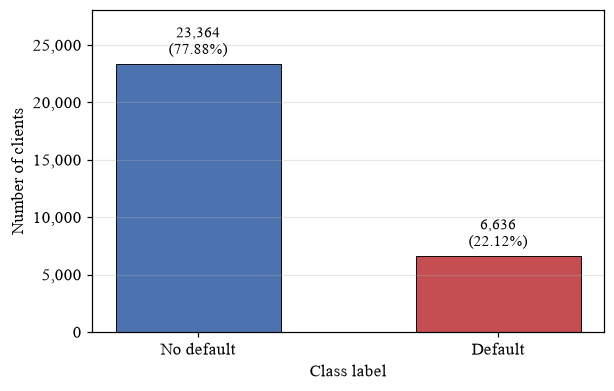

In [4]:
# Counts and percentages of the two target classes.
counts = df[TARGET].value_counts().sort_index()
share = df[TARGET].value_counts(normalize=True).sort_index() * 100
imbalance_ratio = counts[0] / counts[1]

for cls in (0, 1):
    print(f"{CLASS_LABELS[cls]:11s} (y={cls}): {counts[cls]:6,d}  {share[cls]:5.2f}%")
print(f"Imbalance ratio (no default : default) = {imbalance_ratio:.2f} : 1")

# ---- class distribution -------------------------------------------------
fig, ax = plt.subplots(figsize=(6.0, 3.8))
bars = ax.bar(
    [CLASS_LABELS[0], CLASS_LABELS[1]],
    counts.values,
    width=0.55,
    color=[COLORS[0], COLORS[1]],
    edgecolor="black",
    linewidth=0.6,
)

# Write the count and the percentage above each bar.
for bar, cls in zip(bars, (0, 1)):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + counts.max() * 0.02,
        f"{counts[cls]:,}\n({share[cls]:.2f}%)",
        ha="center", va="bottom", fontsize=10,
    )

ax.set_ylabel("Number of clients")
ax.set_xlabel("Class label")
ax.set_ylim(0, counts.max() * 1.20)
ax.yaxis.set_major_formatter(lambda x, pos: f"{x:,.0f}")   # 20,000 instead of 20000
ax.grid(axis="x", visible=False)

fig.savefig(OUT_DIR / "fig_3_1_target_distribution.png")
plt.show()

## 3.3 Descriptive statistics and feature distributions

Table 3.2 summarises the 20 numeric predictors. Figure 3.2 compares four key predictors across
the two classes; the x-axis of each panel is limited to the 1st-99th percentile range so that a
small number of very large values does not hide the shape of the distribution. This is a display
choice only, no value is removed from the data.

In [5]:
# Table 3.2: descriptive statistics for the 20 numeric predictors.
table_3_2 = pd.DataFrame({
    "Variable": num_cols,
    "Mean": df[num_cols].mean().values,
    "Std": df[num_cols].std().values,
    "Min": df[num_cols].min().values,
    "Median": df[num_cols].median().values,
    "Max": df[num_cols].max().values,
    "Skewness": df[num_cols].skew().values,
})

# Round only for presentation.
table_3_2 = table_3_2.round(2)

# The most skewed predictors, quoted in section 3.4 of the report.
skew_rank = df[num_cols].skew().sort_values(ascending=False)
print("Five most skewed predictors:")
print(skew_rank.head(5).round(2).to_string())

table_3_2

Five most skewed predictors:
PAY_AMT2    30.45
PAY_AMT3    17.22
PAY_AMT1    14.67
PAY_AMT4    12.90
PAY_AMT5    11.13


,Variable,Mean,Std,Min,Median,Max,Skewness
0,LIMIT_BAL,167484.32,129747.66,10000.0,140000.0,1000000.0,0.99
1,AGE,35.49,9.22,21.0,34.0,79.0,0.73
2,PAY_0,-0.02,1.12,-2.0,0.0,8.0,0.73
3,PAY_2,-0.13,1.20,-2.0,0.0,8.0,0.79
4,PAY_3,-0.17,1.20,-2.0,0.0,8.0,0.84
5,PAY_4,-0.22,1.17,-2.0,0.0,8.0,1.00
6,PAY_5,-0.27,1.13,-2.0,0.0,8.0,1.01
7,PAY_6,-0.29,1.15,-2.0,0.0,8.0,0.95
8,BILL_AMT1,51223.33,73635.86,-165580.0,22381.5,964511.0,2.66
9,BILL_AMT2,49179.08,71173.77,-69777.0,21200.0,983931.0,2.71


Mean value by class:
                            LIMIT_BAL   AGE  BILL_AMT1  PAY_AMT1
default.payment.next.month                                      
No default                   178099.7  35.4    51994.2    6307.3
Default                      130109.7  35.7    48509.2    3397.0


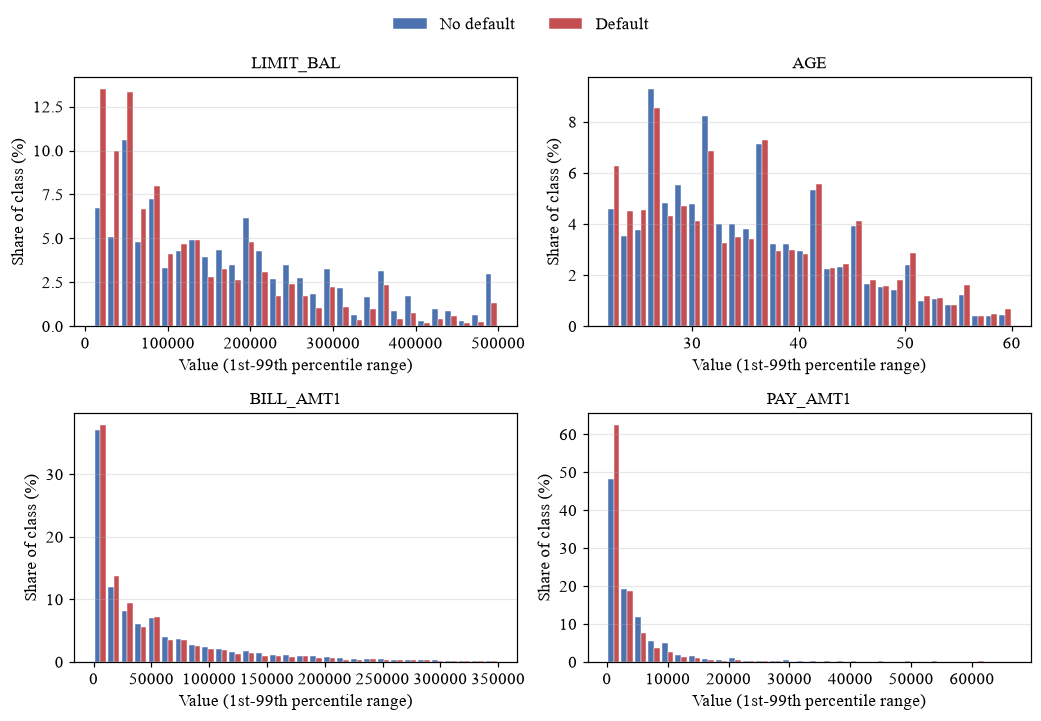

In [6]:
# ---- four key predictors, split by class ---------------------------------
plot_cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]

# Group means make the visual difference in the panels quotable in the report text.
class_means = df.groupby(TARGET)[plot_cols].mean().round(1)
print("Mean value by class:")
print(class_means.rename(index=CLASS_LABELS).to_string())

fig, axes = plt.subplots(2, 2, figsize=(9.6, 6.6))

for ax, col in zip(axes.ravel(), plot_cols):
    # Show the bulk of the data (1st-99th percentile) so the shape stays readable.
    lo, hi = np.percentile(df[col], [1, 99])
    edges = np.linspace(lo, hi, 31)              # 30 equal-width bins
    centres = (edges[:-1] + edges[1:]) / 2
    bar_width = (edges[1] - edges[0]) * 0.42

    # The two classes are drawn side by side, so the bars never overlap and the
    # colours never blend. Each bar is the percentage of its own class in that bin.
    for cls, offset in ((0, -bar_width / 2), (1, bar_width / 2)):
        values = df.loc[df[TARGET] == cls, col]
        counts_in_bin, _ = np.histogram(values, bins=edges)
        bin_share = counts_in_bin / len(values) * 100
        ax.bar(centres + offset, bin_share, width=bar_width,
               color=COLORS[cls], edgecolor="white", linewidth=0.3,
               label=CLASS_LABELS[cls])

    ax.set_title(col, fontsize=11)
    ax.set_xlabel("Value (1st-99th percentile range)")
    ax.set_ylabel("Share of class (%)")
    ax.grid(axis="x", visible=False)

# A single legend for the whole figure keeps the four panels uncluttered.
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))

fig.savefig(OUT_DIR / "fig_3_2_feature_distributions.png")
plt.show()

## 3.4 Data quality issues

Nine checks, each of which has a direct consequence for modelling later in the report:
missing values, duplicate records, undocumented categorical codes, the negative repayment-status
codes, negative bill amounts, extreme skewness, constant predictors, IQR outliers and label noise.
Nothing is changed here.

In [7]:
print("=== 3.4  DATA QUALITY CHECKS (audit only, no modification) ===\n")

# 1) Missing values -------------------------------------------------------
print("1) Missing values")
print(f"   Total missing cells: {n_missing}  |  worst column: {int(df.isna().sum().max())}")

# 2) Duplicate records ----------------------------------------------------
# 35 of the 56 repeated rows also repeat the target; the other 21 carry the
# opposite label for exactly the same 23 predictor values.
dup_rows = df[df.duplicated(subset=feature_cols, keep=False)]
zero_activity = (dup_rows[[f"BILL_AMT{i}" for i in range(1, 7)]].sum(axis=1) == 0) & \
                (dup_rows[[f"PAY_AMT{i}" for i in range(1, 7)]].sum(axis=1) == 0)
n_zero_activity = int(zero_activity.sum())

print("\n2) Duplicate records")
print(f"   {len(dup_groups)} groups of identical profiles cover {dup_group_rows} rows "
      f"(48 groups of 2 clients, 4 groups of 3).")
print(f"   {n_dup_predictors} rows repeat an earlier row on the 23 predictors; "
      f"{n_dup_exact} of them also repeat the label (exact duplicates).")
print(f"   In {n_mixed_groups} groups the same profile carries both labels ({n_mixed_rows} records),")
print("   so those records cannot be separated by any model built on these inputs.")
print(f"   {n_zero_activity} of the {dup_group_rows} rows have zero bills and zero payments in all six")
print("   months (dormant accounts), so identical profiles reflect real client behaviour.")

# 3) Undocumented categorical codes --------------------------------------
print("\n3) Categorical codes")
for col in cat_cols:
    print(f"   {col:10s} observed codes: {sorted(df[col].unique().tolist())}")

undoc_edu = int(df["EDUCATION"].isin([0, 5, 6]).sum())
undoc_mar = int((df["MARRIAGE"] == 0).sum())
print(f"   EDUCATION 0/5/6 (not in the codebook): {undoc_edu} rows ({undoc_edu / len(df) * 100:.2f}%)")
print(f"   MARRIAGE 0        (not in the codebook): {undoc_mar} rows ({undoc_mar / len(df) * 100:.2f}%)")

# 4) Repayment-status codes ----------------------------------------------
# The codebook defines -1 (paid in full), 1-9 (months delayed); -2 is undocumented
# and 0 collides with the balance-paid sign used by the older version of the file.
pay_cols = ["PAY_0"] + [f"PAY_{i}" for i in range(2, 7)]
print("\n4) Repayment-status codes (PAY_0, PAY_2 ... PAY_6)")
for col in pay_cols:
    n_neg2 = int((df[col] == -2).sum())
    n_neg1 = int((df[col] == -1).sum())
    print(f"   {col:7s} min {df[col].min():2d}  max {df[col].max():2d}   "
          f"-2: {n_neg2:5,d}   -1: {n_neg1:5,d}")

# 5) Negative bill amounts ----------------------------------------------
bill_cols = [f"BILL_AMT{i}" for i in range(1, 7)]
neg_share = {c: float((df[c] < 0).mean() * 100) for c in bill_cols}
print("\n5) Negative bill amounts (% of rows)")
for col in bill_cols:
    print(f"   {col:10s} {neg_share[col]:.2f}%")

# 6) Extreme skewness ---------------------------------------------------
print("\n6) Skewness above 5")
heavy_skew = skew_rank[skew_rank > 5]
print("   " + ", ".join(f"{k} ({v:.2f})" for k, v in heavy_skew.items()))

# 7) Constant predictors ------------------------------------------------
constant = [c for c in feature_cols if df[c].nunique() == 1]
print("\n7) Constant predictors:", constant if constant else "none")

print("\nNote: every issue above is resolved in Chapter 4, not here.")

=== 3.4  DATA QUALITY CHECKS (audit only, no modification) ===

1) Missing values
   Total missing cells: 0  |  worst column: 0

2) Duplicate records
   52 groups of identical profiles cover 108 rows (48 groups of 2 clients, 4 groups of 3).
   56 rows repeat an earlier row on the 23 predictors; 35 of them also repeat the label (exact duplicates).
   In 21 groups the same profile carries both labels (46 records),
   so those records cannot be separated by any model built on these inputs.
   97 of the 108 rows have zero bills and zero payments in all six
   months (dormant accounts), so identical profiles reflect real client behaviour.

3) Categorical codes
   SEX        observed codes: [1, 2]
   EDUCATION  observed codes: [0, 1, 2, 3, 4, 5, 6]
   MARRIAGE   observed codes: [0, 1, 2, 3]
   EDUCATION 0/5/6 (not in the codebook): 345 rows (1.15%)
   MARRIAGE 0        (not in the codebook): 54 rows (0.18%)

4) Repayment-status codes (PAY_0, PAY_2 ... PAY_6)
   PAY_0   min -2  max  8   -2: 2

Table 3.3 documents the coding of the three categorical variables, including the undocumented
codes, together with the default rate of each group.

In [8]:
# Table 3.3: codes, frequencies, shares and default rates.
# "Documented" flags the codes that the official codebook does not define.
code_rows = []
for col in cat_cols:
    for code, n in df[col].value_counts().sort_index().items():
        subset = df.loc[df[col] == code, TARGET]
        is_undocumented = (col == "EDUCATION" and code in (0, 5, 6)) or \
                          (col == "MARRIAGE" and code == 0)
        code_rows.append((
            col, int(code), int(n),
            n / len(df) * 100,
            subset.mean() * 100,
            "No" if is_undocumented else "Yes",
        ))

table_3_3 = pd.DataFrame(
    code_rows,
    columns=["Variable", "Code", "Frequency", "Share (%)", "Default rate (%)", "Documented"],
).round({"Share (%)": 2, "Default rate (%)": 2})

table_3_3

,Variable,Code,Frequency,Share (%),Default rate (%),Documented
0,SEX,1,11888,39.63,24.17,Yes
1,SEX,2,18112,60.37,20.78,Yes
2,EDUCATION,0,14,0.05,0.00,No
3,EDUCATION,1,10585,35.28,19.23,Yes
4,EDUCATION,2,14030,46.77,23.73,Yes
5,EDUCATION,3,4917,16.39,25.16,Yes
6,EDUCATION,4,123,0.41,5.69,Yes
7,EDUCATION,5,280,0.93,6.43,No
8,EDUCATION,6,51,0.17,15.69,No
9,MARRIAGE,0,54,0.18,9.26,No


### 3.4b Outliers and noise

The IQR audit below flags 9.0% of numeric cells. Most flags are valid tail values, especially the
discrete repayment-status codes, so no rows are removed. The 21 profiles with both labels are
label noise: they cap attainable accuracy but are retained because either label could be genuine.

In [9]:
# 3.4b IQR outlier audit for the 20 numeric predictors.
q1 = df[num_cols].quantile(0.25)
q3 = df[num_cols].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

outlier_mask = (df[num_cols] < lower) | (df[num_cols] > upper)
outlier_counts = outlier_mask.sum()
outlier_share = outlier_counts / len(df) * 100

table_3_4 = pd.DataFrame({
    "Variable": num_cols,
    "IQR lower": lower.values,
    "IQR upper": upper.values,
    "Outliers n": outlier_counts.values,
    "Share (%)": outlier_share.values,
})
table_3_4.round(2).to_csv(OUT_DIR / "table03_04_iqr_outliers.csv", index=False)

print(f"Outlier cells: {outlier_counts.sum():,} of {len(df) * len(num_cols):,} "
      f"({outlier_counts.sum() / (len(df) * len(num_cols)) * 100:.2f}%)")
print(f"Profiles with both labels: {n_mixed_groups} ({n_mixed_rows} rows, "
      f"{n_mixed_rows / len(df) * 100:.2f}%)")
table_3_4.round(2)

Outlier cells: 54,001 of 600,000 (9.00%)
Profiles with both labels: 21 (46 rows, 0.15%)


,Variable,IQR lower,IQR upper,Outliers n,Share (%)
0,LIMIT_BAL,-235000.00,525000.00,167,0.56
1,AGE,8.50,60.50,272,0.91
2,PAY_0,-2.50,1.50,3130,10.43
3,PAY_2,-2.50,1.50,4410,14.70
4,PAY_3,-2.50,1.50,4209,14.03
5,PAY_4,-2.50,1.50,3508,11.69
6,PAY_5,-2.50,1.50,2968,9.89
7,PAY_6,-2.50,1.50,3079,10.26
8,BILL_AMT1,-91739.62,162389.38,2400,8.00
9,BILL_AMT2,-88547.50,155538.50,2395,7.98


## 3.5 Feature relationships and multicollinearity

Pearson correlations are computed on the 23 predictors plus the target, using the same coefficient
that Chapter 4 applies for feature ranking. Figure 3.3 is the heatmap of that matrix.

In [10]:
# Pearson correlation matrix (23 predictors + target).
corr_cols = num_cols + cat_cols + [TARGET]
corr = df[corr_cols].corr(method="pearson")

# Correlation of every predictor with the target, strongest first.
target_corr = corr[TARGET].drop(TARGET)
target_corr = target_corr.reindex(target_corr.abs().sort_values(ascending=False).index)

print("Top 10 predictors by |r| with the target:")
print(target_corr.head(10).round(3).to_string())

Top 10 predictors by |r| with the target:
PAY_0        0.325
PAY_2        0.264
PAY_3        0.235
PAY_4        0.217
PAY_5        0.204
PAY_6        0.187
LIMIT_BAL   -0.154
PAY_AMT1    -0.073
PAY_AMT2    -0.059
PAY_AMT4    -0.057


In [11]:
# Multicollinearity: keep only the lower triangle of the predictor-predictor block,
# then rank the pairs by absolute correlation.
pred_corr = corr.loc[feature_cols, feature_cols]
lower_mask = np.tril(np.ones(pred_corr.shape), k=-1).astype(bool)
pairs = pred_corr.where(lower_mask).stack()
pairs = pairs.reindex(pairs.abs().sort_values(ascending=False).index)

strong_pairs = pairs[pairs.abs() >= 0.80]
print(f"Predictor pairs with |r| >= 0.80: {len(strong_pairs)}")
print(strong_pairs.head(10).round(3).to_string())

Predictor pairs with |r| >= 0.80: 17
BILL_AMT2  BILL_AMT1    0.951
BILL_AMT6  BILL_AMT5    0.946
BILL_AMT5  BILL_AMT4    0.940
BILL_AMT3  BILL_AMT2    0.928
BILL_AMT4  BILL_AMT3    0.924
BILL_AMT6  BILL_AMT4    0.901
BILL_AMT4  BILL_AMT2    0.892
BILL_AMT3  BILL_AMT1    0.892
BILL_AMT5  BILL_AMT3    0.884
BILL_AMT4  BILL_AMT1    0.860


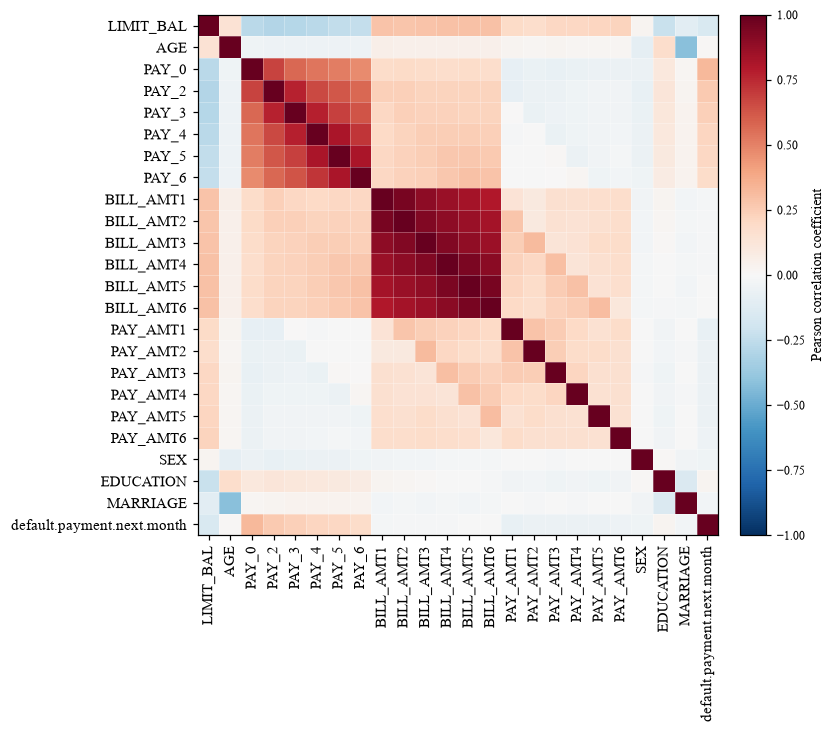

In [12]:
# ---- full correlation heatmap --------------------------------------------
# The matrix is 24 x 24; per-cell numbers cannot be read at the width used in
# the report, so colour carries the pattern and the text quotes the key values.
values = corr.values
n = len(corr_cols)

fig, ax = plt.subplots(figsize=(8.4, 6.8))
image = ax.imshow(values, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(n))
ax.set_yticks(range(n))
ax.set_xticklabels(corr_cols, rotation=90, fontsize=10)
ax.set_yticklabels(corr_cols, fontsize=10)
ax.grid(False)

# Thin white grid lines keep the 24 x 24 cells distinguishable.
ax.set_xticks([x - 0.5 for x in range(1, n)], minor=True)
ax.set_yticks([y - 0.5 for y in range(1, n)], minor=True)
ax.grid(which="minor", color="white", linewidth=0.6)
ax.tick_params(which="minor", length=0)

colorbar = fig.colorbar(image, ax=ax, fraction=0.046, pad=0.03)
colorbar.set_label("Pearson correlation coefficient", fontsize=9)
colorbar.ax.tick_params(labelsize=8)

fig.tight_layout()
fig.savefig(OUT_DIR / "fig_3_3_correlation_heatmap.png")
plt.show()

## 3.6 Implications for modelling

Collect the numbers that Chapter 3 quotes into one printed block, so that the report text and the
notebook can never disagree. Only the figures are written to disk.

In [13]:
print("=== 3.6  KEY NUMBERS FOR THE REPORT ===\n")

print(f"Sample                : {len(df):,} clients, {len(feature_cols)} predictors "
      f"({len(num_cols)} numeric, {len(cat_cols)} categorical)")
print(f"Missing values        : {n_missing}")
print(f"Duplicate records     : {n_dup_predictors} rows repeat an earlier profile, "
      f"{n_dup_exact} are exact; {n_mixed_groups} profiles carry both labels ({n_mixed_rows} records)")
print(f"Class balance         : {counts[0]:,} / {counts[1]:,} = {share[0]:.2f}% / {share[1]:.2f}% "
      f"(ratio {imbalance_ratio:.2f}:1)")
print(f"Undocumented codes    : EDUCATION 0/5/6 {undoc_edu} rows, MARRIAGE 0 {undoc_mar} rows")
print(f"Negative bill amounts : {min(neg_share.values()):.2f}% to {max(neg_share.values()):.2f}% of rows")
print(f"Highest skewness      : {skew_rank.index[0]} {skew_rank.iloc[0]:.2f} "
      f"({len(heavy_skew)} PAY_AMT columns above 5)")
print("Strongest target corr : " + ", ".join(f"{k} {v:+.3f}" for k, v in target_corr.head(3).items()))
print(f"High correlation pairs: {len(strong_pairs)} pairs with |r| >= 0.80")
print(f"Constant predictors   : {constant if constant else 'none'}")

print("\nFigures written to", OUT_DIR, ":")
for path in sorted(OUT_DIR.glob("*.png")):
    print(" -", path.name, f"({path.stat().st_size / 1024:.1f} KB)")

=== 3.6  KEY NUMBERS FOR THE REPORT ===

Sample                : 30,000 clients, 23 predictors (20 numeric, 3 categorical)
Missing values        : 0
Duplicate records     : 56 rows repeat an earlier profile, 35 are exact; 21 profiles carry both labels (46 records)
Class balance         : 23,364 / 6,636 = 77.88% / 22.12% (ratio 3.52:1)
Undocumented codes    : EDUCATION 0/5/6 345 rows, MARRIAGE 0 54 rows
Negative bill amounts : 1.97% to 2.29% of rows
Highest skewness      : PAY_AMT2 30.45 (6 PAY_AMT columns above 5)
Strongest target corr : PAY_0 +0.325, PAY_2 +0.264, PAY_3 +0.235
High correlation pairs: 17 pairs with |r| >= 0.80
Constant predictors   : none

Figures written to ..\outputs\chapter_03 :
 - fig_3_1_target_distribution.png (55.7 KB)
 - fig_3_2_feature_distributions.png (196.8 KB)
 - fig_3_3_correlation_heatmap.png (256.2 KB)
